# 05 · Los modelos base: ¿cuánto aporta el MDA?

Hasta aquí se sabe que el MDA es un buen pronóstico del MTR y que se equivoca sobre todo en energía (notebook 02). La primera decisión del proyecto es cómo usarlo. Hay dos caminos: ignorarlo y pronosticar el MTR solo con su propia historia, o tomarlo como punto de partida y aprender cuánto corregirlo.

Se prueba con LEAR (el modelo lineal de referencia de la literatura, notebook 04), con redes neuronales y con gradient boosting, y se revisa si el modelo se limita a copiar al MDA. Todo se mide en desarrollo (julio a diciembre de 2024), en MXN/MWh y como cambio porcentual contra el MDA (221.6). El test sigue cerrado.

In [1]:
import os
for k in ('OMP_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'MKL_NUM_THREADS'): os.environ[k] = '1'   # evita sobresuscripción en procesos paralelos
import sys, warnings, time, pickle
from pathlib import Path
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / 'src'))
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from dataclasses import replace
from pml import plotstyle as ps
ps.aplicar()
FIG = ROOT / 'reports/figures'; REP = ROOT / 'reports'

# Contexto, periodo de desarrollo y las referencias contra las que se mide todo
from pml import features2 as f2, exp, dl, gb2, referencias as rf
from pml.metrics import mae
c0 = f2.cargar_ctx(); DEV = exp.idx_dev(); DIAS = exp.dias_eval(c0); Y, X = c0.Y, c0.X
cb = replace(c0, escala=0.5); W = 0.01        # escala asinh × 0.5 y recorte del 1% al entrenar (notebook 04)
f = lambda d: d.loc[DEV].values
refs = {'MDA': mae(f(Y), f(X)), 'naive d-14': mae(f(Y), f(Y.shift(14)))}
# atajo: entrena (o lee de caché) un LEAR con los grupos de variables `g` y devuelve su pronóstico en MXN/MWh
corre = lambda nombre, g, **kw: exp.correr_y_evaluar(kw.pop('c', cb), nombre, g, winsor=W, centro='mediana', **kw)[0]
# LEAR base: rezagos del MTR y del MDA (con su error). Es el punto de partida de todo el proyecto
BASE = LEAR = corre('Bm x0.5 winsor 1%', ['G0', 'G2'])
# anota cada red probada en el registro de experimentos (reports/experimentos.csv)
def reg(nombre, variante, hp, P, nota=''):
    exp.registrar(nombre, dl.GRUPOS_V[variante], variante, 0, mae(f(Y), f(P)), f'red {hp.arch}; {nota}')
# el error transformado (diferencia MTR − MDA en la escala del proyecto) en formato largo, para el gradient boosting
Yt, Xt = f2._t(cb); SP = Yt - Xt
sp_long = SP.stack(); sp_long.index.names = ['fecha', 'hora']
def preparar(grupos):
    F, _ = f2.construir(cb, grupos); L = gb2.a_largo(F)
    y = pd.Series(sp_long.reindex(pd.MultiIndex.from_frame(L[['fecha', 'hora']])).values, index=L.index)
    return F, L, y, [x for x in L.columns if x != 'fecha']
# "nulo": el MDA más la mediana de su error histórico conocido (lo que haría un modelo sin ninguna variable)
m_ = np.array([np.median(SP.loc[f2.TRAIN_START:d - pd.Timedelta(days=8)].values) for d in DEV])
NULO = pd.DataFrame(f2.inv(Xt.loc[DEV].values + m_[:, None], cb), index=DEV, columns=X.columns)
print(f"MDA {refs['MDA']:.1f} | LEAR base {mae(f(Y), f(LEAR)):.1f}  (MAE de desarrollo, MXN/MWh)")

MDA 221.6 | LEAR base 219.2  (MAE de desarrollo, MXN/MWh)


## 1. ¿Cuánto pesa el MDA?

In [2]:
# ¿Cuánto pesa el MDA? Se compara el LEAR completo con versiones que sólo ven la historia del MTR o sólo el MDA
FC = {'MDA': X, 'nulo (MDA + mediana del spread)': NULO}
# objetivo "mtr": el modelo pronostica el precio directamente, sin anclarse al MDA
P = exp.correr_config(cb, 'solo G0 nivel', ['G0'], objetivo='mtr', winsor=W, centro='mediana')
FC['solo historia del MTR, nivel (G0)'], _ = exp.pronostico(cb, P, 'mtr')
exp.registrar('solo G0 nivel', ['G0'], 'mtr', 96, mae(f(Y), f(FC['solo historia del MTR, nivel (G0)'])))
FC['solo MTR, objetivo spread (G0)'] = corre('solo G0', ['G0'])
FC['solo MDA e historial (G2)'] = corre('solo G2', ['G2'])
FC['base (G0 + G2)'] = BASE
T = exp.legible(exp.tabla_dev(c0, FC, 'MDA', [k for k in FC if k != 'MDA'], refs).drop(columns='dMAE_pct')); display(T); T.to_csv(REP / '05_peso_mda_dev.csv')

,MAE,MAE sin días de pico,vs MDA (%),p,meses mejor,de
MDA,221.62,168.33,0.00,NaN,<NA>,<NA>
nulo (MDA + mediana del spread),222.38,169.59,0.34,0.006,1,6
"solo historia del MTR, nivel (G0)",268.05,215.28,20.95,0.000,0,6
"solo MTR, objetivo spread (G0)",225.02,171.36,1.54,0.002,0,6
solo MDA e historial (G2),220.39,168.27,-0.55,0.280,4,6
base (G0 + G2),219.22,166.61,-1.08,0.237,5,6


Sin el MDA, LEAR es 21% peor que el MDA (268.1 contra 221.6). Usarlo como punto de partida pero corrigiendo solo con la historia del MTR sigue siendo peor (+1.5%). El MDA con su historial de errores ya le gana por poco (−0.6%), y sumarle el MTR de días anteriores baja otro medio punto (−1.1%, el LEAR base).

La información está en el MDA; la historia del MTR, con el rezago de ocho días disponible, agrega poco. Por eso LEAR se parece tanto al MDA.

El MDA se queda como ancla: los modelos pronostican cuánto corregirlo, no el precio desde cero. Falta ver si modelos más flexibles sacan más provecho de la historia.

## 2. Las redes neuronales y el MDA

In [3]:
# Primera búsqueda de hiperparámetros de la DNN (MLP de dos capas) y de NBEATSx, con la variante "nivel" (el MDA es una
# entrada más). Cada configuración se entrena con reentrenamiento semanal y se guarda en caché
BUSQ, MEJOR1 = {}, {}
for arch in ('mlp', 'nbeats'):
    filas = []
    for i, hp in enumerate(dl.busqueda(arch)):
        t = time.time(); P = dl.a_precios(cb, dl.correr_dl(cb, 'nivel', hp, DEV, nombre=f'busq_{arch}{i}'), 'nivel')
        reg(f'busqueda {arch} {i}', 'nivel', hp, P, 'búsqueda de hiperparámetros')
        filas.append(dict(config=i, capa1=hp.n1, capa2=hp.n2 if arch == 'mlp' else '-', bloques=hp.n_bloques if arch == 'nbeats' else '-', activación=hp.act,
                          dropout=hp.dropout, lr=hp.lr, L1=hp.l1, MAE=mae(f(Y), f(P))))
    BUSQ[arch] = pd.DataFrame(filas).set_index('config')
    MEJOR1[arch] = replace(dl.busqueda(arch)[int(BUSQ[arch].MAE.idxmin())], seeds=4)
    print(f'{arch}: MAE de desarrollo entre {BUSQ[arch].MAE.min():.1f} y {BUSQ[arch].MAE.max():.1f} según la configuración')

mlp: MAE de desarrollo entre 236.9 y 256.1 según la configuración
nbeats: MAE de desarrollo entre 236.8 y 268.2 según la configuración


La primera búsqueda dejó a las redes en ≈237, 7% peor que el MDA. Antes de concluir que no sirven, se probó una red sin capas ocultas, casi un LEAR: con la penalización de la búsqueda quedaba 15% peor que LEAR; con una penalización fuerte (3) llega a 220.7, casi igual a LEAR (219.2).

In [4]:
# Control: una red lineal (sin capas ocultas) con distintas penalizaciones L1. Si con L1 fuerte se parece a LEAR, la
# primera búsqueda estaba poco regularizada
lin = {}
for l1, nombre in [(1e-3, 'lineal_spread'), (0.03, 'reg_lineal_0.03'), (0.3, 'reg_lineal_0.3'), (3.0, 'reg_lineal_3.0')]:
    hp = dl.HP(arch='lineal', lr=1e-3, l1=l1, patience=30, epochs=300, seeds=4 if l1 == 1e-3 else 2)
    lin[l1] = mae(f(Y), f(dl.a_precios(cb, dl.correr_dl(cb, 'spread', hp, DEV, nombre=nombre), 'spread')))
print('red lineal (objetivo spread), MAE de desarrollo según L1:', {k: round(v, 1) for k, v in lin.items()}, '| LEAR base', round(mae(f(Y), f(LEAR)), 1))

red lineal (objetivo spread), MAE de desarrollo según L1: {0.001: 254.0, 0.03: 261.4, 0.3: 252.6, 3.0: 220.7} | LEAR base 219.2


El problema era el exceso de libertad: con ~300 días de entrenamiento y ~300 entradas, una red sin freno memoriza ruido.

Se repitió la búsqueda con penalizaciones fuertes (0.3 a 10). Con ellas, las redes que corrigen al MDA bajan de ≈227 a ≈222.

In [5]:
# Segunda búsqueda, con L1 fuerte, para las variantes "nivel" y "spread" (la red pronostica MTR − MDA)
BUSQ2, MEJOR = {}, {}
for arch in ('mlp', 'nbeats'):
    filas = []
    for i, hp in enumerate(dl.busqueda_reg(arch)):
        r = dict(config=i, capa1=hp.n1, capa2=hp.n2 if arch == 'mlp' else '-', bloques=hp.n_bloques if arch == 'nbeats' else '-', activación=hp.act,
                 dropout=hp.dropout, lr=hp.lr, L1=hp.l1)
        for v in ('nivel', 'spread'):
            P = dl.a_precios(cb, dl.correr_dl(cb, v, hp, DEV, nombre=f'busq2_{arch}{i}_{v}'), v)
            reg(f'busqueda2 {arch} {i} {v}', v, hp, P, 'segunda búsqueda (L1 fuerte)'); r[f'MAE {v}'] = mae(f(Y), f(P))
        filas.append(r)
    BUSQ2[arch] = pd.DataFrame(filas).set_index('config')
    MEJOR[arch] = replace(dl.busqueda_reg(arch)[int(BUSQ2[arch]['MAE spread'].idxmin())], seeds=4)
    print(arch, '→ elegida la configuración', int(BUSQ2[arch]['MAE spread'].idxmin())); print(f"   MAE de desarrollo corrigiendo al MDA: entre {BUSQ2[arch]['MAE spread'].min():.1f} y {BUSQ2[arch]['MAE spread'].max():.1f}; apuntando al precio directo: entre {BUSQ2[arch]['MAE nivel'].min():.1f} y {BUSQ2[arch]['MAE nivel'].max():.1f}")

mlp → elegida la configuración 3
   MAE de desarrollo corrigiendo al MDA: entre 221.7 y 227.1; apuntando al precio directo: entre 234.5 y 241.9


nbeats → elegida la configuración 5
   MAE de desarrollo corrigiendo al MDA: entre 222.3 y 279.4; apuntando al precio directo: entre 238.6 y 270.0


Con penalización fuerte, ganan las configuraciones más restringidas, igual que en LEAR. Con esa configuración se comparan cuatro formas de darle el MDA a la red:

In [6]:
# Las cuatro formas de usar el MDA (V1 sin MDA, V2 como entrada, V3 pronosticar el error, V4 MDA intermitente),
# con la mejor configuración de cada red
NOMBRE = {'sin_mda': 'V1 sin MDA', 'nivel': 'V2 nivel', 'spread': 'V3 spread', 'mda_drop': 'V4 MDA intermitente'}
NN, V4 = {}, {}
for arch, etiqueta in (('mlp', 'DNN'), ('nbeats', 'NBEATSx')):
    hp = MEJOR[arch]
    for v in NOMBRE:
        P = dl.correr_dl(cb, v, hp, DEV, nombre=f'{arch}_{v}_r2')
        # V4 da dos salidas (con y sin MDA); se prueban varios pesos w entre ellas
        if v == 'mda_drop':
            V4[etiqueta] = {w: dl.a_precios(cb, w * P['con'] + (1 - w) * P['sin'], v) for w in (0, .25, .5, .75, 1)}
            NN[f'{etiqueta} {NOMBRE[v]} (w = 1)'] = V4[etiqueta][1]
        else:
            NN[f'{etiqueta} {NOMBRE[v]}'] = dl.a_precios(cb, P, v)
for k, P in NN.items(): reg(k, 'spread' if 'V3' in k else 'nivel', MEJOR['mlp' if k.startswith('DNN') else 'nbeats'], P, 'variante del papel del MDA')
FV = {'MDA': X, 'LEAR base': LEAR, **NN}
T = exp.legible(exp.tabla_dev(c0, FV, 'MDA', [k for k in FV if k != 'MDA'], refs).drop(columns='dMAE_pct')); display(T); T.to_csv(REP / '05_variantes_dev.csv')
print('V4: MAE de desarrollo según el peso w de la salida con MDA (w = 0: solo la salida sin MDA)')
display(pd.DataFrame({k: {w: mae(f(Y), f(P)) for w, P in d.items()} for k, d in V4.items()}).T.round(1))

,MAE,MAE sin días de pico,vs MDA (%),p,meses mejor,de
MDA,221.62,168.33,0.00,NaN,<NA>,<NA>
LEAR base,219.22,166.61,-1.08,0.237,5,6
DNN V1 sin MDA,260.15,197.39,17.38,0.000,1,6
DNN V2 nivel,236.95,171.15,6.92,0.001,1,6
DNN V3 spread,221.34,168.81,-0.13,0.617,4,6
DNN V4 MDA intermitente (w = 1),250.61,185.69,13.08,0.000,1,6
NBEATSx V1 sin MDA,257.58,193.58,16.23,0.000,1,6
NBEATSx V2 nivel,237.89,172.22,7.34,0.001,1,6
NBEATSx V3 spread,222.88,170.62,0.57,0.901,2,6
NBEATSx V4 MDA intermitente (w = 1),250.51,186.58,13.04,0.000,1,6


V4: MAE de desarrollo según el peso w de la salida con MDA (w = 0: solo la salida sin MDA)


,0.00,0.25,0.50,0.75,1.00
DNN,263.7,259.1,255.3,252.5,250.6
NBEATSx,260.6,256.8,253.9,251.8,250.5


Sin MDA (V1) las redes son 16–17% peores; con el MDA como una entrada más (V2), 7% peores; corrigiéndolo (V3), quedan igual que el MDA (DNN −0.1%, NBEATSx +0.6%); alternar con y sin MDA durante el entrenamiento (V4) es 13% peor.

Con ~300 días la red no logra descubrir sola que "el MTR se parece al MDA" es casi siempre el mejor punto de partida; hay que dárselo. Corrigiendo al MDA empata con él y no supera a LEAR (219.2). Las redes sin MDA quedan mucho peor, pero su error es distinto al del MDA, y eso las vuelve útiles para mezclar (notebook 10).

Para las redes también se parte del MDA. Las variantes V1 (sin MDA) y V3 (corrigiendo al MDA) son las que se siguen usando.

## 3. El gradient boosting, solo con Monclova

In [7]:
# Gradient boosting (GB) sobre las mismas variables que LEAR. Se prueban dos tamaños de árbol y se elige en desarrollo.
# Las predicciones se guardan en caché porque tardan
CACHE = ROOT / 'data/processed/gb2_cache.pkl'
GBP = pickle.loads(CACHE.read_bytes()) if CACHE.exists() else {}
if not all(('GB base G0+G2', i) in GBP for i in range(len(gb2.GRID))):
    F, L, y, cols = preparar(['G0', 'G2'])
    for i, prm in enumerate(gb2.GRID): GBP[('GB base G0+G2', i)] = gb2.correr(L, y, cols, DIAS, prm, F.index.min())
    CACHE.write_bytes(pickle.dumps(GBP))
a_precio = lambda P: f2.inv(P + Xt.loc[P.index], cb)
sc = {i: mae(f(Y), f(a_precio(GBP[('GB base G0+G2', i)]))) for i in range(len(gb2.GRID))}
GB = a_precio(GBP[('GB base G0+G2', min(sc, key=sc.get))])
print('MAE de desarrollo por configuración:', {gb2.GRID[i]['max_leaf_nodes']: round(v, 1) for i, v in sc.items()})
# el GB solo y mezclado con LEAR y con el MDA
FG = {'MDA': X, 'LEAR base': LEAR, 'GB base': GB, 'LEAR + GB (50/50)': (LEAR + GB) / 2, 'LEAR + GB + MDA (1/3)': (LEAR + GB + X) / 3}
T = exp.legible(exp.tabla_dev(c0, FG, 'MDA', [k for k in FG if k != 'MDA'], refs).drop(columns='dMAE_pct')); display(T); T.to_csv(REP / '05_gb_dev.csv')

MAE de desarrollo por configuración: {7: 229.4, 15: 230.3}


,MAE,MAE sin días de pico,vs MDA (%),p,meses mejor,de
MDA,221.62,168.33,0.00,NaN,<NA>,<NA>
LEAR base,219.22,166.61,-1.08,0.237,5,6
GB base,229.35,176.50,3.49,0.014,2,6
LEAR + GB (50/50),221.10,168.89,-0.23,0.498,3,6
LEAR + GB + MDA (1/3),219.67,167.10,-0.88,0.232,6,6


El gradient boosting solo con Monclova queda 3.5% peor que el MDA (229.4, p = 0.014) y peor que LEAR; mezclado con LEAR no mejora a LEAR solo.

Con ~330 días la flexibilidad extra se va en memorizar ruido. El problema no es el modelo sino la cantidad de ejemplos.

Es la semilla del notebook 06: ¿qué pasa si se le dan más ejemplos, de otros nodos de la red?

## 4. ¿El modelo copia al MDA o corrige?

tamaño típico de la corrección del modelo: mediana |LEAR − MDA| = 20.9 MXN/MWh
tamaño típico de la sorpresa real:        mediana |MTR − MDA|  = 57.4 MXN/MWh
correlación de Spearman entre corrección y sorpresa: 0.27
el modelo acierta la dirección de la sorpresa en 59% de las horas


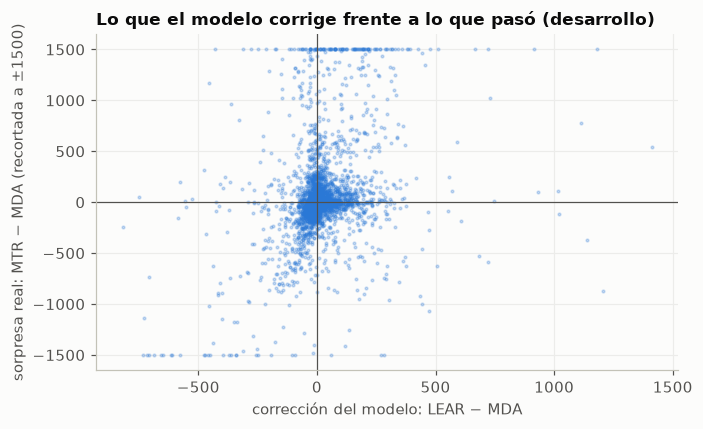

In [8]:
# ¿Cuánto corrige el modelo y qué tan bien? Se compara su corrección (LEAR − MDA) con la sorpresa real (MTR − MDA)
corr_mod = (BASE - X).loc[DEV].values.ravel(); corr_real = (Y - X).loc[DEV].values.ravel()
print(f'tamaño típico de la corrección del modelo: mediana |LEAR − MDA| = {np.median(np.abs(corr_mod)):.1f} MXN/MWh')
print(f'tamaño típico de la sorpresa real:        mediana |MTR − MDA|  = {np.median(np.abs(corr_real)):.1f} MXN/MWh')
print(f'correlación de Spearman entre corrección y sorpresa: {pd.Series(corr_mod).corr(pd.Series(corr_real), method="spearman"):.2f}')
acierta = np.sign(corr_mod) == np.sign(corr_real)
print(f'el modelo acierta la dirección de la sorpresa en {100 * acierta.mean():.0f}% de las horas')
# Figura: cada punto es una hora de desarrollo
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.scatter(corr_mod, np.clip(corr_real, -1500, 1500), s=3, alpha=.25, color=ps.AZUL)
ax.axhline(0, color=ps.GRIS, lw=.8); ax.axvline(0, color=ps.GRIS, lw=.8)
ax.set_xlabel('corrección del modelo: LEAR − MDA'); ax.set_ylabel('sorpresa real: MTR − MDA (recortada a ±1500)')
ax.set_title('Lo que el modelo corrige frente a lo que pasó (desarrollo)'); fig.tight_layout(); fig.savefig(FIG / '05_correccion_vs_sorpresa.png'); plt.show()

LEAR corrige al MDA en una magnitud típica de 21 MXN/MWh, y la sorpresa real típica es de 57. Las correcciones se parecen a lo que pasó (correlación 0.27; acierta la dirección en 59% de las horas, contra 50% del azar).

No copia al MDA: corrige poco, pero en la dirección correcta. La mayor parte de la sorpresa, que se decide en tiempo real, no se puede anticipar el día anterior.

## 5. Medir el error en proporción

In [9]:
# ¿Ayuda pronosticar la diferencia en proporción (MTR / MDA) en lugar de en pesos (MTR − MDA)? LEAR y TiDE, contra su versión en pesos
R = rf.cargar()
FILAS = [('referencia', 'MDA', X, None), ('LEAR', 'LEAR base', LEAR, None), ('LEAR', 'LEAR en proporción', R.P['LEAR log-razón'], 'LEAR base'),
         ('TiDE', 'TiDE', R.P['TiDE V3'], None), ('TiDE', 'TiDE en proporción', R.P['TiDE V3 log-razón'], 'TiDE')]
T = exp.comparar(Y, FILAS, X); display(T); T.to_csv(REP / '05_proporcion_dev.csv')

MAE  vs MDA (%) referencia vs referencia (%)  \
grupo      modelo                                                               
referencia MDA                 221.6         0.0                                
LEAR       LEAR base           219.2        -1.1                                
           LEAR en proporción  217.8        -1.7  LEAR base              -0.6   
TiDE       TiDE                219.7        -0.8                                
           TiDE en proporción  218.0        -1.6       TiDE              -0.8   

                              meses mejor      p  
grupo      modelo                                 
referencia MDA                                    
LEAR       LEAR base                              
           LEAR en proporción      2 de 6  0.172  
TiDE       TiDE                                   
           TiDE en proporción      5 de 6  0.049

Pronosticar la diferencia en proporción (MTR / MDA) en lugar de en pesos mejora 0.6% a LEAR (2 de 6 meses, p = 0.17) y 0.8% a TiDE (5 de 6 meses, p = 0.049). TiDE es la red que mejor se defiende, con 219.7 contra 221.3 de la DNN y 222.9 de NBEATSx.

En proporción, equivocarse por 100 en un día de 500 pesa igual que por 600 en un día de 3,000, y el modelo se obsesiona menos con los días caros. La ganancia es chica y poco consistente en LEAR (2 de 6 meses), algo más clara en TiDE (5 de 6).

Las versiones en proporción de LEAR y TiDE quedan como candidatas junto a las de siempre.

## Decisiones

- El MDA es el ancla: los modelos pronostican cuánto corregirlo.
- Las redes necesitan penalización fuerte, y aun así solo empatan con el MDA. El GB solo con Monclova queda peor.
- Se mantienen modelos que no ven el MDA (V1), por su valor como pieza de mezcla, y las versiones en proporción de LEAR y TiDE.
- Siguiente pregunta: el GB y las redes tienen pocos ejemplos para aprender. ¿Y si se entrenan con más nodos de la red? (notebook 06)